In [ ]:
# Lab 1 · Unit 3 · PLNA (MUIA): political tweet classification
# Author: Álvaro Vázquez · Kaggle: Sash Vazquez

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd

from utils.dataLoader import loadTrain, loadTest, saveSubmission, splitTrainValidationTest, TEXT_COLUMN, TARGET_COLUMN, ID_COLUMN
from utils.corpusStats import classDistribution, lengthStats, noiseStats, topTokensByClass
from utils.textNormalizer import TextNormalizer, applyRegex, buildViews
from utils.corpusCache import loadOrNormalize
from utils.metrics import compareModels, classificationReport, saveMetrics

from core.baselineModels import TfidfClassifier
from core.embeddingModels import Word2VecClassifier
from core.pipeline import ClassificationPipeline

from utils.plotting import plotClassDistribution, plotLengthDistribution, plotNoiseStats, plotConfusionMatrix, plotF1PerClass

In [3]:
# 1. Exploratory analysis
trainDf = loadTrain()
trainDf.shape

(208349, 3)

In [4]:
testDf = loadTest()
testDf.shape

(36768, 2)

In [5]:
trainDf.head()

,id,target,tweet
0,1,podemos,"Hoy y cada día os aplaudimos, igual que cada d..."
1,2,pp,Sesión #DiputaciónPermanente con debate conval...
2,4,psoe,Buenos días! Imagine Dragons - Demons (Officia...
3,5,vox,Desenmascarando al Foro de São Paulo https://t...
4,6,psoe,Ayer vimos un ejemplo de lo peor de la polític...


In [6]:
classDistribution(trainDf)

,count,share
target,,
psoe,52061,0.2499
vox,43733,0.2099
podemos,41282,0.1981
pp,38564,0.1851
ciudadanos,32709,0.1570


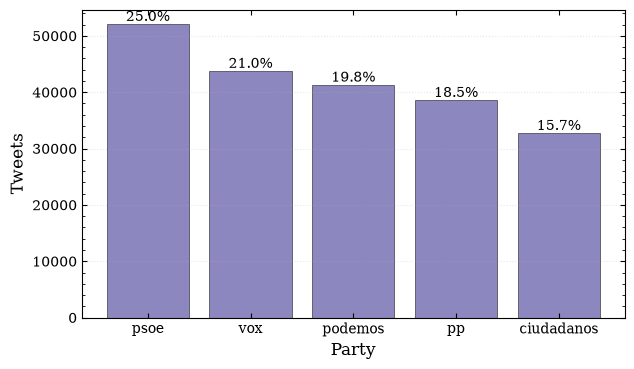

In [7]:
plotClassDistribution(trainDf)

In [8]:
lengthStats(trainDf)

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
ciudadanos,32709.0,33.7,12.9,1.0,27.0,38.0,43.0,70.0
podemos,41282.0,32.3,13.7,1.0,23.0,37.0,43.0,70.0
pp,38564.0,30.1,13.9,1.0,19.0,33.0,42.0,64.0
psoe,52061.0,31.2,13.1,1.0,21.0,35.0,42.0,75.0
vox,43733.0,27.4,15.3,1.0,14.0,29.0,41.0,84.0


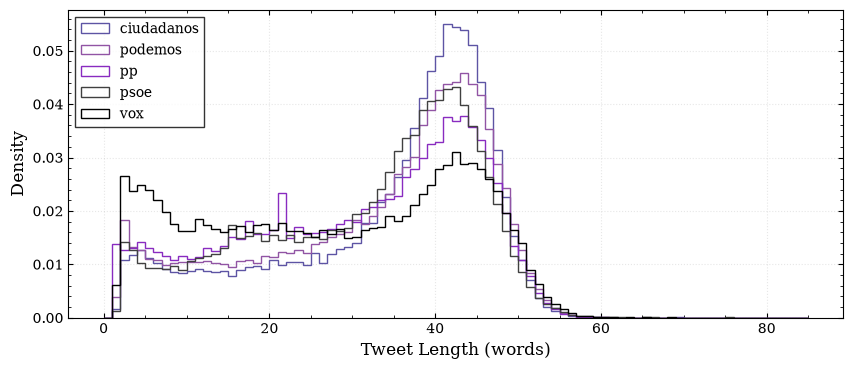

In [9]:
plotLengthDistribution(trainDf)

In [10]:
noiseSummary = noiseStats(trainDf)
noiseSummary

,url,mention,hashtag,emoji
target,,,,
ciudadanos,0.887,0.551,0.395,0.503
podemos,0.756,0.420,0.237,0.427
pp,0.852,0.541,0.303,0.413
psoe,0.826,0.663,0.440,0.450
vox,0.753,0.409,0.168,0.242
all,0.811,0.521,0.310,0.403


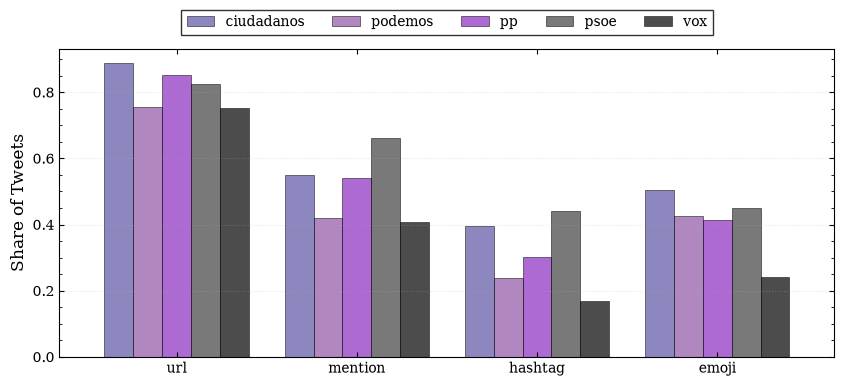

In [11]:
plotNoiseStats(noiseSummary)

In [12]:
topTokensByClass(trainDf, pattern=r'@\w+')

,ciudadanos,podemos,pp,psoe,vox
0,@inesarrimadas,@irenemontero,@pablocasado_,@sanchezcastejon,@santi_abascal
1,@baledmundo,@ionebelarra,@populares,@adrilastra,@vox_es
2,@ciudadanoscs,@pabloiglesias,@teogarciaegea,@elperiodico_esp,@macarena_olona
3,@albert_rivera,@podemos,@cucagamarra,@psoe,@ivanedlm
4,@carrizosacarlos,@pablo_iglesias_,@nunezfeijoo,@elperiodico,@ortega_smith
5,@congreso_es,@yolanda_diaz_,@idiazayuso,@mjmonteroc,@jorgebuxade
6,@begonavillacis,@isaserras,@montesinospablo,@abalosmeco,@vox_congreso
7,@juanmarin_cs,@s,@feijoogalicia,@felipe_sicilia,@gaceta_es
8,@guillermodiazcs,@pabloechenique,@alferma1,@congreso_es,@igarrigavaz
9,@franciscoigea,@_pablofdez_,@almeidapp_,@salvadorilla,@monasterior


In [13]:
topTokensByClass(trainDf, pattern=r'#\w+')

,ciudadanos,podemos,pp,psoe,vox
0,#actualidadcs,#hartura,#regióndemurcia,#cmin,#españasiempre
1,#endirecto,#niunamenos,#portodoloquenosune,#avanzamos_,#españaviva
2,#andalucía,#cmin,#españa,#psoe,#cambioreal
3,#covid19,#unideotoño2021,#memoria,#votapsoe,#siembra
4,#elcambioquefunciona,#lafuerzaquetransforma,#unacataluñamejor,#estevirusloparamosunidos,#recuperemoscataluña
5,#políticaútil,#ungobiernocontigo,#loharemosbien,#elgobiernodelagente,#soloquedavox
6,#pleno,#laemergenciadevox,#endirecto,#laespañaquehacemos_,#protegemadrid
7,#españaenmarcha,#covid19,#lafuerzaquenosmueve,#planderecuperación,#agendaespaña
8,#valencia,#quehablelamayoría,#preparados,#cumplimos,#viva21
9,#vamosmadrid,#sísepuede,#votapp,#españaavanza_,#vox


In [14]:
# 2. Cleaning and normalization
normalizerParams = {
    'removeStopwords': True,
    'keepNegation': True,
    'keepEmojis': True,
    'mergeEntities': True,
    'spacyModel': 'es_core_news_sm'
}

In [15]:
normalizer = TextNormalizer(**normalizerParams)

In [16]:
samples = trainDf[TEXT_COLUMN].sample(5, random_state=42)

pd.DataFrame({
    'original': samples,
    'regex': samples.map(applyRegex),
    'normalized': samples.map(lambda tweet: ' '.join(normalizer.normalize(tweet))),
})

,original,regex,normalized
176299,No tienen vergüenza! https://t.co/snRIREE3i7,No tienen vergüenza! _URL_,no vergüenza _URL_
109842,Con @_JuanEspadas gana Huelva y toda la socied...,Con @_JuanEspadas gana Huelva y toda la socied...,@_juanespadas ganar huelva sociedad andaluz si...
2538,Nuestros adversarios dedicaron ayer su tiempo ...,Nuestros adversarios dedicaron ayer su tiempo ...,adversario dedicar ayer tiempo ruido momento n...
87881,"Son los de siempre, los de antes, los caciques...","Son los de siempre, los de antes, los caciques...",caciqu terrateniente señalar dedo campesinoson...
152405,📩 Ya puedes votar en https://t.co/ajJT6BSQ15 s...,:sobre_con_flecha: Ya puedes votar en _URL_ so...,:sobre_con_flecha: poder votar _URL_ postura p...


In [17]:
# 3. Tokenization and vocabulary
trainTokens = loadOrNormalize(trainDf[TEXT_COLUMN], normalizer, cacheName='trainLemmas')
trainTokens.shape

(208349,)

In [18]:
testTokens = loadOrNormalize(testDf[TEXT_COLUMN], normalizer, cacheName='testLemmas')
testTokens.shape

(36768,)

In [19]:
trainTokens.head()

0    [aplaudir, dejáis, piel, cuidarno, personal, s...
1    [sesión, #diputaciónpermanente, debate, conval...
2    [imagine_dragons, demons, official_video, _URL...
3            [desenmascarar, foro_de_são_paulo, _URL_]
4    [ayer, ver, ejemplo, política, insulto, machis...
dtype: object

In [20]:
trainViews = buildViews(trainDf[TEXT_COLUMN], trainTokens)
testViews = buildViews(testDf[TEXT_COLUMN], testTokens)
trainViews.head()

,raw,lemmas
0,"hoy y cada día os aplaudimos, igual que cada d...","[aplaudir, dejáis, piel, cuidarno, personal, s..."
1,sesión #diputaciónpermanente con debate conval...,"[sesión, #diputaciónpermanente, debate, conval..."
2,buenos días! imagine dragons - demons (officia...,"[imagine_dragons, demons, official_video, _URL..."
3,desenmascarando al foro de são paulo _url_,"[desenmascarar, foro_de_são_paulo, _URL_]"
4,ayer vimos un ejemplo de lo peor de la polític...,"[ayer, ver, ejemplo, política, insulto, machis..."


In [21]:
vocabulary = pd.Series([token for tokens in trainTokens for token in tokens]).value_counts()

{
    'vocabularySize': len(vocabulary),
    'meanTokensPerTweet': round(float(trainTokens.str.len().mean()), 1),
    'emptyTweets': int((trainTokens.str.len() == 0).sum()),
}

{'vocabularySize': 151043, 'meanTokensPerTweet': 15.5, 'emptyTweets': 21}

In [22]:
vocabulary.head(20)

_URL_                                      180336
no                                          67313
gobierno                                    22633
españa                                      20877
año                                         12969
español                                     12959
:dorso_de_mano_con_índice_a_la_derecha:     11391
seguir                                      11345
sánchez                                     10610
pp                                          10367
país                                        10126
gracias                                      9975
:rosa:                                       9750
ni                                           9245
derecho                                      8990
psoe                                         7893
público                                      7832
política                                     7761
ley                                          7725
mujer                                        7325


In [23]:
labels = trainDf[TARGET_COLUMN]

In [24]:
trainIdx, validationIdx, testIdx = splitTrainValidationTest(labels, validationSize=0.15, testSize=0.15, randomSeed=42)
len(trainIdx), len(validationIdx), len(testIdx)

(145844, 31252, 31253)

In [25]:
# 4-5. Vector representation and models
paramsLogreg = {
    'featureBlocks': [
        {'view': 'lemmas', 'analyzer': 'word', 'ngramRange': (1, 1), 'minDf': 2},
    ],
    'classifier': 'logreg',
    'C': 4.0,
    'classWeight': 'balanced',
    'randomSeed': 42
}

In [26]:
modelLogreg = TfidfClassifier(**paramsLogreg)

In [27]:
pipelineLogreg = ClassificationPipeline(model=modelLogreg)

In [28]:
predictionsLogreg, actualsLogreg, metricsLogreg = pipelineLogreg.run(
    trainViews,
    labels,
    validationSize=0.15,
    testSize=0.15,
    randomSeed=42,
)

In [29]:
metricsLogreg

{'accuracy': 0.7837578394982722,
 'precisionMacro': 0.7792412890033821,
 'recallMacro': 0.7800571209780791,
 'f1Macro': 0.7793522988839838,
 'f1PerClass': {'ciudadanos': 0.7338336588876324,
  'podemos': 0.7983877341341974,
  'pp': 0.7557849462365591,
  'psoe': 0.8256190161769561,
  'vox': 0.7831361389845739}}

In [30]:
paramsSvm = {
    'featureBlocks': [
        {'view': 'lemmas', 'analyzer': 'word', 'ngramRange': (1, 2), 'minDf': 2},
    ],
    'classifier': 'svm',
    'C': 0.5,
    'classWeight': 'balanced',
    'randomSeed': 42
}

In [31]:
modelSvm = TfidfClassifier(**paramsSvm)

In [32]:
pipelineSvm = ClassificationPipeline(model=modelSvm)

In [33]:
predictionsSvm, actualsSvm, metricsSvm = pipelineSvm.run(
    trainViews,
    labels,
    validationSize=0.15,
    testSize=0.15,
    randomSeed=42,
)

In [34]:
metricsSvm

{'accuracy': 0.8067643670805068,
 'precisionMacro': 0.803575716436006,
 'recallMacro': 0.8021242046648883,
 'f1Macro': 0.8022887223295807,
 'f1PerClass': {'ciudadanos': 0.7584311237974416,
  'podemos': 0.8202203297132589,
  'pp': 0.78058889560487,
  'psoe': 0.8444794125360608,
  'vox': 0.8077238499962722}}

In [35]:
paramsSvmChars = {
    'featureBlocks': [
        {'view': 'lemmas', 'analyzer': 'word', 'ngramRange': (1, 2), 'minDf': 2},
        {'view': 'lemmas', 'analyzer': 'char', 'ngramRange': (2, 5), 'minDf': 2, 'maxFeatures': 500000},
    ],
    'classifier': 'svm',
    'C': 0.3,
    'classWeight': 'balanced',
    'randomSeed': 42
}

In [36]:
modelSvmChars = TfidfClassifier(**paramsSvmChars)

In [37]:
pipelineSvmChars = ClassificationPipeline(model=modelSvmChars)

In [38]:
predictionsSvmChars, actualsSvmChars, metricsSvmChars = pipelineSvmChars.run(
    trainViews,
    labels,
    validationSize=0.15,
    testSize=0.15,
    randomSeed=42,
)

In [39]:
metricsSvmChars

{'accuracy': 0.8150838346345833,
 'precisionMacro': 0.8120045573132701,
 'recallMacro': 0.8100164099693126,
 'f1Macro': 0.8104861945857357,
 'f1PerClass': {'ciudadanos': 0.7626599006237446,
  'podemos': 0.8304977945809704,
  'pp': 0.7936673625608908,
  'psoe': 0.852204539525176,
  'vox': 0.8134013756378966}}

In [40]:
paramsSvmRawLemmas = {
    'featureBlocks': [
        {'view': 'raw', 'analyzer': 'word', 'ngramRange': (1, 2), 'minDf': 2},
        {'view': 'raw', 'analyzer': 'char', 'ngramRange': (2, 5), 'minDf': 3, 'maxFeatures': 500000},
        {'view': 'lemmas', 'analyzer': 'word', 'ngramRange': (1, 2), 'minDf': 2},
    ],
    'classifier': 'svm',
    'C': 0.3,
    'classWeight': 'balanced',
    'randomSeed': 42
}

In [41]:
modelSvmRawLemmas = TfidfClassifier(**paramsSvmRawLemmas)

In [42]:
pipelineSvmRawLemmas = ClassificationPipeline(model=modelSvmRawLemmas)

In [43]:
predictionsSvmRawLemmas, actualsSvmRawLemmas, metricsSvmRawLemmas = pipelineSvmRawLemmas.run(
    trainViews,
    labels,
    validationSize=0.15,
    testSize=0.15,
    randomSeed=42,
)

In [44]:
metricsSvmRawLemmas

{'accuracy': 0.826955074875208,
 'precisionMacro': 0.8235872373131299,
 'recallMacro': 0.8215658161919333,
 'f1Macro': 0.822172204997009,
 'f1PerClass': {'ciudadanos': 0.7722960151802657,
  'podemos': 0.84704390553178,
  'pp': 0.8014641798849573,
  'psoe': 0.8629000907088247,
  'vox': 0.8271568336792173}}

In [45]:
paramsWord2Vec = {
    'view': 'lemmas',
    'vectorSize': 200,
    'window': 5,
    'minCount': 2,
    'epochs': 10,
    'C': 1.0,
    'classWeight': 'balanced',
    'randomSeed': 42
}

In [46]:
modelWord2Vec = Word2VecClassifier(**paramsWord2Vec)

In [47]:
pipelineWord2Vec = ClassificationPipeline(model=modelWord2Vec)

In [48]:
predictionsWord2Vec, actualsWord2Vec, metricsWord2Vec = pipelineWord2Vec.run(
    trainViews,
    labels,
    validationSize=0.15,
    testSize=0.15,
    randomSeed=42,
)

In [49]:
metricsWord2Vec

{'accuracy': 0.6590938179956483,
 'precisionMacro': 0.655516173341088,
 'recallMacro': 0.656207053370516,
 'f1Macro': 0.6552311838969898,
 'f1PerClass': {'ciudadanos': 0.6099989734113541,
  'podemos': 0.6644158291457286,
  'pp': 0.6436702311141773,
  'psoe': 0.696559617585673,
  'vox': 0.6615112682280159}}

In [50]:
modelWord2Vec.mostSimilar('sánchez', topn=5)

[('pedro_sánchez', 0.8198579549789429),
 ('gobierno_de_sánchez', 0.8069126605987549),
 ('sanchez', 0.6710547804832458),
 ('sanchismo', 0.6129041910171509),
 ('independentista', 0.5972712635993958)]

In [51]:
paramsNbSvm = {
    'featureBlocks': [
        {'view': 'raw', 'analyzer': 'word', 'ngramRange': (1, 2), 'minDf': 2},
        {'view': 'raw', 'analyzer': 'char', 'ngramRange': (1, 6), 'minDf': 3, 'maxFeatures': 1500000},
        {'view': 'lemmas', 'analyzer': 'word', 'ngramRange': (1, 2), 'minDf': 2},
    ],
    'classifier': 'nbsvm',
    'C': 0.3,
    'classWeight': 'balanced',
    'randomSeed': 42
}

In [52]:
modelNbSvm = TfidfClassifier(**paramsNbSvm)

In [53]:
pipelineNbSvm = ClassificationPipeline(model=modelNbSvm)

In [54]:
predictionsNbSvm, actualsNbSvm, metricsNbSvm = pipelineNbSvm.run(
    trainViews,
    labels,
    validationSize=0.15,
    testSize=0.15,
    randomSeed=42,
)

In [55]:
metricsNbSvm

{'accuracy': 0.8358185076155126,
 'precisionMacro': 0.8329576853999876,
 'recallMacro': 0.8303123725350622,
 'f1Macro': 0.8313387350870821,
 'f1PerClass': {'ciudadanos': 0.7881867259447444,
  'podemos': 0.8533141899976071,
  'pp': 0.8064516129032258,
  'psoe': 0.869231261601485,
  'vox': 0.8395098849883484}}

In [56]:
metricsByModel = {
    'word2VecLogreg': metricsWord2Vec,
    'tfidfLogreg': metricsLogreg,
    'tfidfSvm': metricsSvm,
    'tfidfSvmChars': metricsSvmChars,
    'tfidfSvmRawLemmas': metricsSvmRawLemmas,
    'tfidfNbSvm': metricsNbSvm,
}

In [57]:
for name, metrics in metricsByModel.items():
    saveMetrics(name, metrics)

In [58]:
compareModels(metricsByModel)

,accuracy,precisionMacro,recallMacro,f1Macro,f1 ciudadanos,f1 podemos,f1 pp,f1 psoe,f1 vox
tfidfNbSvm,0.8358,0.8330,0.8303,0.8313,0.7882,0.8533,0.8065,0.8692,0.8395
tfidfSvmRawLemmas,0.8270,0.8236,0.8216,0.8222,0.7723,0.8470,0.8015,0.8629,0.8272
tfidfSvmChars,0.8151,0.8120,0.8100,0.8105,0.7627,0.8305,0.7937,0.8522,0.8134
tfidfSvm,0.8068,0.8036,0.8021,0.8023,0.7584,0.8202,0.7806,0.8445,0.8077
tfidfLogreg,0.7838,0.7792,0.7801,0.7794,0.7338,0.7984,0.7558,0.8256,0.7831
word2VecLogreg,0.6591,0.6555,0.6562,0.6552,0.6100,0.6644,0.6437,0.6966,0.6615


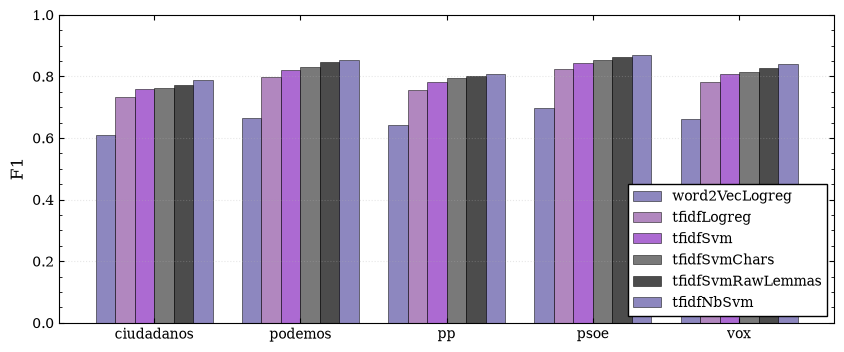

In [59]:
plotF1PerClass(metricsByModel)

In [60]:
# 6. Evaluation of the selected model on the held-out split
predictionsTestSplit, actualsTestSplit, metricsTestSplit = pipelineNbSvm.test(trainViews, labels)
metricsTestSplit

{'accuracy': 0.8354397977794131,
 'precisionMacro': 0.8319140555727584,
 'recallMacro': 0.8294712613993512,
 'f1Macro': 0.8304353291699476,
 'f1PerClass': {'ciudadanos': 0.7827648114901257,
  'podemos': 0.8560903339473052,
  'pp': 0.8010344827586207,
  'psoe': 0.8738000767950851,
  'vox': 0.838486940858601}}

In [61]:
classificationReport(actualsTestSplit, predictionsTestSplit)

,precision,recall,f1-score,support
ciudadanos,0.8122,0.7554,0.7828,4906.0000
podemos,0.8492,0.8631,0.8561,6193.0000
pp,0.7990,0.8031,0.8010,5785.0000
psoe,0.8734,0.8742,0.8738,7809.0000
vox,0.8258,0.8515,0.8385,6560.0000
accuracy,0.8354,0.8354,0.8354,0.8354
macro avg,0.8319,0.8295,0.8304,31253.0000
weighted avg,0.8352,0.8354,0.8351,31253.0000


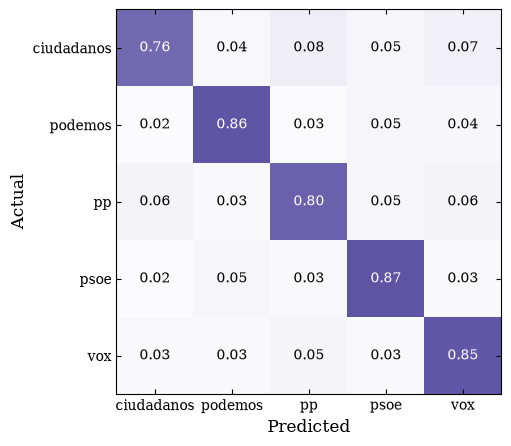

In [62]:
plotConfusionMatrix(actualsTestSplit, predictionsTestSplit)

In [63]:
# 7. Submissions
pipelineNbSvm.fitFull(trainViews, labels)
predictionsTest = pipelineNbSvm.predict(testViews)
predictionsTest.shape

(36768,)

In [64]:
submission = saveSubmission(testDf[ID_COLUMN], predictionsTest, 'outputs/submissionTfidfNbSvm.csv')
submission.head()

,id,target
0,3,podemos
1,8,vox
2,9,ciudadanos
3,11,ciudadanos
4,14,ciudadanos


In [65]:
pipelineSvmChars.fitFull(trainViews, labels)
predictionsTestChars = pipelineSvmChars.predict(testViews)
submissionChars = saveSubmission(testDf[ID_COLUMN], predictionsTestChars, 'outputs/submissionTfidfSvmChars.csv')
submissionChars.head()

,id,target
0,3,podemos
1,8,ciudadanos
2,9,ciudadanos
3,11,ciudadanos
4,14,ciudadanos
